# Breast Cancer Histopathology Classification with Deep Learning

Dataset exploration: structure, class balance, dimensions, and representative images.

> Research and educational use only; not a clinical diagnostic system.


In [1]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd

DATASET_ROOT = Path(r"C:\Users\Dell_PC_admin\.cache\kagglehub\datasets\forderation\breakhis-400x\versions\1") / "BreaKHis 400X"
if not DATASET_ROOT.exists():
    raise FileNotFoundError(f"Dataset directory not found: {DATASET_ROOT}")
print(f"Dataset: {DATASET_ROOT}")


Dataset: C:\Users\Dell_PC_admin\.cache\kagglehub\datasets\forderation\breakhis-400x\versions\1\BreaKHis 400X


In [2]:
image_paths = sorted(path for path in DATASET_ROOT.rglob("*") if path.is_file() and path.suffix.lower() in {".png", ".jpg", ".jpeg"})
if not image_paths:
    raise RuntimeError("No image files were found.")
records = []
for path in image_paths:
    parts = path.relative_to(DATASET_ROOT).parts
    records.append({"path": path, "split": parts[0], "label": next((p for p in parts if p.lower() in {"benign", "malignant"}), "unknown")})
images = pd.DataFrame(records)
print(f"Total images: {len(images):,}")
display(images.head())


Total images: 1,693


,path,split,label
0,C:\Users\Dell_PC_admin\.cache\kagglehub\datase...,test,benign
1,C:\Users\Dell_PC_admin\.cache\kagglehub\datase...,test,benign
2,C:\Users\Dell_PC_admin\.cache\kagglehub\datase...,test,benign
3,C:\Users\Dell_PC_admin\.cache\kagglehub\datase...,test,benign
4,C:\Users\Dell_PC_admin\.cache\kagglehub\datase...,test,benign


In [3]:
print("Images by split and class:")
display(pd.crosstab(images["split"], images["label"], margins=True))
print("\nImages by class:")
display(images["label"].value_counts().rename_axis("label").to_frame("count"))


Images by split and class:


label,benign,malignant,All
split,,,
test,176,369,545
train,371,777,1148
All,547,1146,1693



Images by class:


,count
label,
malignant,1146
benign,547


In [4]:
def image_size(path):
    with Image.open(path) as image:
        return image.width, image.height, image.mode
sizes = pd.DataFrame([image_size(path) for path in images["path"]], columns=["width", "height", "mode"])
print("Image modes:")
display(sizes["mode"].value_counts().rename_axis("mode").to_frame("count"))
print("Image dimensions:")
display(sizes[["width", "height"]].describe())


Image modes:


,count
mode,
RGB,1693


Image dimensions:


,width,height
count,1693.0,1693.000000
mean,700.0,459.969285
std,0.0,0.349267
min,700.0,456.000000
25%,700.0,460.000000
50%,700.0,460.000000
75%,700.0,460.000000
max,700.0,460.000000


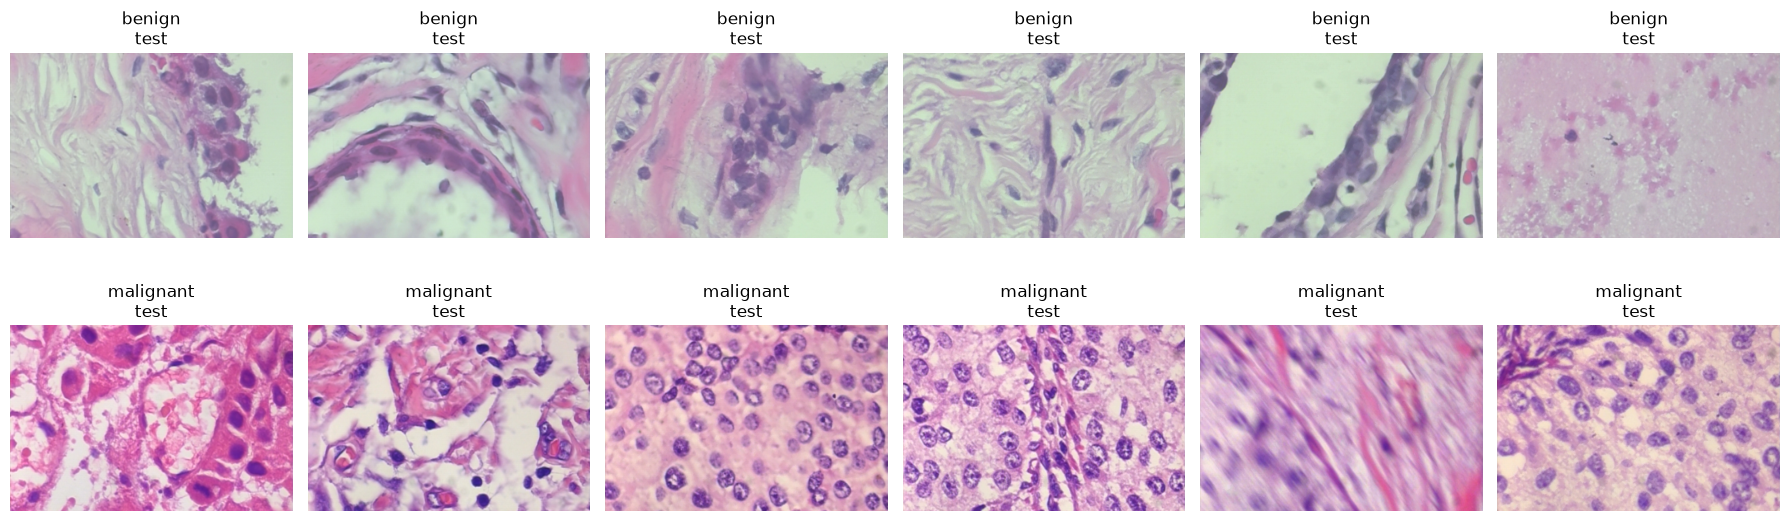

In [5]:
samples = images[images["label"].isin(["benign", "malignant"])].groupby("label", group_keys=False).head(6)
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for axis, (_, row) in zip(axes.flat, samples.iterrows()):
    with Image.open(row["path"]) as image:
        axis.imshow(image)
    axis.set_title(f"{row['label']}\n{row['split']}")
    axis.axis("off")
plt.tight_layout()
plt.show()


## Next steps

After confirming the dataset layout, we can build reproducible data loaders and train a transfer-learning classifier with class-sensitive metrics.
